First five rows of the dataset:
     v1                                                 v2 Unnamed: 2  \
0   ham  Go until jurong point, crazy.. Available only ...        NaN   
1   ham                      Ok lar... Joking wif u oni...        NaN   
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...        NaN   
3   ham  U dun say so early hor... U c already then say...        NaN   
4   ham  Nah I don't think he goes to usf, he lives aro...        NaN   

  Unnamed: 3 Unnamed: 4  
0        NaN        NaN  
1        NaN        NaN  
2        NaN        NaN  
3        NaN        NaN  
4        NaN        NaN  

Dataset information:
<class 'pandas.core.frame.DataFrame'>
Index: 5169 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5169 non-null   object
 1   message  5169 non-null   object
dtypes: object(2)
memory usage: 121.1+ KB
None

Class distribution:
label
ham     4516
spam     653
Na

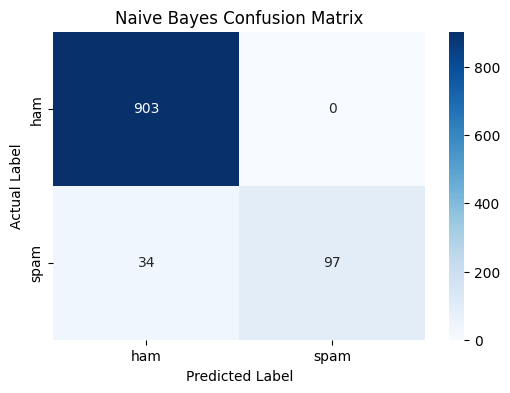


New SMS: Congratulations! You have won a free prize. Claim now
Predicted class: spam
Result: This message is Spam.


In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Step 2: Load the dataset
df = pd.read_csv("spam.csv", encoding="latin-1")

print("First five rows of the dataset:")
print(df.head())

# Step 3: Select required columns
df = df[["v1", "v2"]]
df.columns = ["label", "message"]

# Remove missing values and duplicate messages
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

print("\nDataset information:")
print(df.info())

print("\nClass distribution:")
print(df["label"].value_counts())

# Step 4: Preprocess the text
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", "", text)
    return text.strip()

df["message"] = df["message"].apply(clean_text)

# Remove empty messages
df = df[df["message"] != ""]

# Step 5: Separate input and output
X = df["message"]
y = df["label"]

# Step 6: Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# Step 7: Convert text into TF-IDF features
tfidf = TfidfVectorizer(stop_words="english")

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("\nTraining TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

# Step 8: Train the Naive Bayes classifier
model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

print("\nNaive Bayes model trained successfully.")

# Step 9: Predict the test data
y_pred = model.predict(X_test_tfidf)

# Step 10: Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Step 11: Display the confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["ham", "spam"]
)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["ham", "spam"],
    yticklabels=["ham", "spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Naive Bayes Confusion Matrix")
plt.show()

# Step 12: Predict a new SMS message
new_message = [
    "Congratulations! You have won a free prize. Claim now"
]

new_message_tfidf = tfidf.transform(new_message)
prediction = model.predict(new_message_tfidf)

print("\nNew SMS:", new_message[0])
print("Predicted class:", prediction[0])

if prediction[0] == "spam":
    print("Result: This message is Spam.")
else:
    print("Result: This message is Ham (Normal).")